In [1]:
import pandas as pd
import matplotlib.pyplot as plt # visualization library

In [2]:
storage = pd.read_excel("../data/NG_STOR_WKLY_S1_W.xls") # this command reads the first sheet in the excel file by default

In [3]:
storage.head() # displays the first 5 rows of the data frame so we can quickly get an idea what's in the excel file

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6
0,NaN,Workbook Contents,NaN,NaN,NaN,NaN,NaN
1,NaN,Weekly Working Gas in Underground Storage,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,Click worksheet name or tab at bottom for data,NaN,NaN,NaN,NaN,NaN
4,NaN,Worksheet Name,Description,# Of Series,Frequency,Latest Data for,NaN


In [4]:
pd.ExcelFile("../data/NG_STOR_WKLY_S1_W.xls").sheet_names # pd.ExcelFile(...) tells pandas to treat the file as an Excel workbook rather than one sheet

['Contents', 'Data 1']

In [5]:
storage = pd.read_excel("../data/NG_STOR_WKLY_S1_W.xls", sheet_name="Data 1") # now we know the data we want to manipulate is stored in sheet "Data 1"

In [6]:
storage.head()

,Back to Contents,Data 1: Weekly Working Gas in Underground Storage,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,Sourcekey,NW2_EPG0_SWO_R48_BCF,NW2_EPG0_SWO_R31_BCF,NW2_EPG0_SWO_R32_BCF,NW2_EPG0_SWO_R34_BCF,NW2_EPG0_SWO_R35_BCF,NW2_EPG0_SWO_R33_BCF,NW2_EPG0_SSO_R33_BCF,NW2_EPG0_SNO_R33_BCF
1,Date,Weekly Lower 48 States Natural Gas Working Und...,Weekly East Region Natural Gas Working Undergr...,Weekly Midwest Region Natural Gas Working Unde...,Weekly Mountain Region Natural Gas Working Und...,Weekly Pacific Region Natural Gas Working Unde...,Weekly South Central Region Natural Gas Worki...,Weekly Salt South Central Region Natural Gas W...,Weekly Nonsalt South Central Region Natural Ga...
2,2010-01-01 00:00:00,3117,769,900,195,268,985,159,826
3,2010-01-08 00:00:00,2850,703,820,185,257,886,123,763
4,2010-01-15 00:00:00,2607,642,750,176,246,793,91,702


In [7]:
storage = pd.read_excel("../data/NG_STOR_WKLY_S1_W.xls",sheet_name="Data 1",header=2) # with header=2 we're actually saying "Don't treat Excel's first row as the column headers. The actual headers are on the third row."
storage = storage[["Date", "Weekly Lower 48 States Natural Gas Working Underground Storage (Billion Cubic Feet)"]] # select only the dates and the lower 48 storage - leave the individual region data behind
storage.head()

,Date,Weekly Lower 48 States Natural Gas Working Underground Storage (Billion Cubic Feet)
0,2010-01-01,3117
1,2010-01-08,2850
2,2010-01-15,2607
3,2010-01-22,2521
4,2010-01-29,2406


In [8]:
# rename the storage column to something shorter
storage = storage.rename(columns={"Weekly Lower 48 States Natural Gas Working Underground Storage (Billion Cubic Feet)": "storage_bcf"})
storage.head()

,Date,storage_bcf
0,2010-01-01,3117
1,2010-01-08,2850
2,2010-01-15,2607
3,2010-01-22,2521
4,2010-01-29,2406


In [9]:
storage.shape

(874, 2)

In [10]:
storage.info()

<class 'pandas.DataFrame'>
RangeIndex: 874 entries, 0 to 873
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         874 non-null    datetime64[us]
 1   storage_bcf  874 non-null    int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 13.8 KB


In [11]:
# 874 non-null count for date and storage_bcf matches the rows in the previous cell which tells us that there is no missing data
# data types are as to be expected, no "objects"

In [12]:
# let's see how far this data goes until
storage.tail()

,Date,storage_bcf
869,2026-08-28,3214
870,2026-09-04,3254
871,2026-09-11,3298
872,2026-09-18,3351
873,2026-09-25,3415


In [13]:
# calculate the weekly change in natural gas storage
storage["weekly_change_bcf"] = storage["storage_bcf"].diff() # the .diff() method will calculate the difference between the current week's storage and the previous week's storage
storage.head(10)

# positive weekly_change_bcf → injection into storage
# negative weekly_change_bcf → withdrawal from storage

,Date,storage_bcf,weekly_change_bcf
0,2010-01-01,3117,NaN
1,2010-01-08,2850,-267.0
2,2010-01-15,2607,-243.0
3,2010-01-22,2521,-86.0
4,2010-01-29,2406,-115.0
5,2010-02-05,2214,-192.0
6,2010-02-12,2026,-188.0
7,2010-02-19,1853,-173.0
8,2010-02-26,1738,-115.0
9,2010-03-05,1627,-111.0


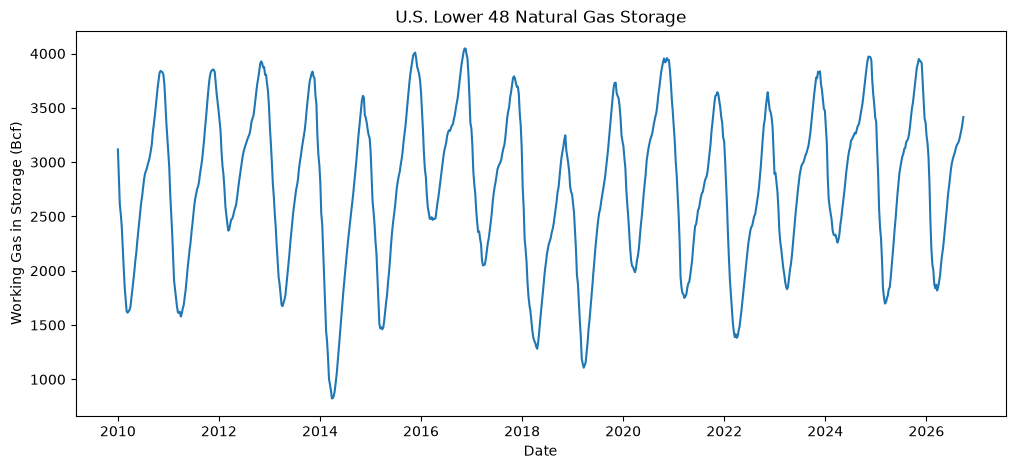

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(storage["Date"], storage["storage_bcf"])

plt.title("U.S. Lower 48 Natural Gas Storage")
plt.xlabel("Date")
plt.ylabel("Working Gas in Storage (Bcf)")

plt.show()

In [15]:
# since henry_hub and production in market_data are monthly, we need one storage observation per month
# convert weekly storage data to month-end observations
monthly_storage = (
    storage
    .set_index("Date") # makes date the index
    .resample("ME") # groups by month instead of daily, "ME" means month end
    .last() # using .last() instead of .mean() because storage is an inventory level - averaging all the weekly storage observations would answer a different question: "What was average storage during the month?" - we just want the latest available level around month-end
    .reset_index() # turns the dates back into a regular column
)

monthly_storage.head()

,Date,storage_bcf,weekly_change_bcf
0,2010-01-31,2406,-115.0
1,2010-02-28,1738,-115.0
2,2010-03-31,1638,12.0
3,2010-04-30,1994,82.0
4,2010-05-31,2357,89.0


In [16]:
# remove weekly_change_bcf column because monthly_storage should contain monthly metrics
monthly_storage = monthly_storage.drop(columns=["weekly_change_bcf"])

# calculate change in storage from the previous month's ending level
monthly_storage["monthly_change_bcf"] = monthly_storage["storage_bcf"].diff()

monthly_storage.head()

,Date,storage_bcf,monthly_change_bcf
0,2010-01-31,2406,NaN
1,2010-02-28,1738,-668.0
2,2010-03-31,1638,-100.0
3,2010-04-30,1994,356.0
4,2010-05-31,2357,363.0


In [17]:
# extract the calendar month from each date
monthly_storage["month_number"] = monthly_storage["Date"].dt.month
monthly_storage.head()

# the goal is to calculate the average storage amount across all Januaries, then do the same for all Februaries, all Marches, etc.

,Date,storage_bcf,monthly_change_bcf,month_number
0,2010-01-31,2406,NaN,1
1,2010-02-28,1738,-668.0,2
2,2010-03-31,1638,-100.0,3
3,2010-04-30,1994,356.0,4
4,2010-05-31,2357,363.0,5


In [18]:
# Split all 202 monthly observations into 12 groups based on month_number, then calculate the average storage_bcf within each group
# calculate the historical average storage level for each calendar month
storage_normals = (
    monthly_storage
    .groupby("month_number")["storage_bcf"]
    .mean()
)

storage_normals

# .groupby("month_number") means split the rows into groups based on month number (Jan = 1, Feb = 2, etc.)
# ["storage_bcf"] means from those groups, we're interested in the storage column
# .mean() will calculate the average storage within each group

month_number
1     2507.882353
2     1938.411765
3     1740.294118
4     1938.000000
5     2344.470588
6     2686.294118
7     2891.705882
8     3089.588235
9     3409.529412
10    3747.312500
11    3711.250000
12    3260.562500
Name: storage_bcf, dtype: float64

In [19]:
# assign the appropriate historical monthly average to each observation
monthly_storage["storage_normal_bcf"] = (monthly_storage["month_number"].map(storage_normals))
monthly_storage.head()

,Date,storage_bcf,monthly_change_bcf,month_number,storage_normal_bcf
0,2010-01-31,2406,NaN,1,2507.882353
1,2010-02-28,1738,-668.0,2,1938.411765
2,2010-03-31,1638,-100.0,3,1740.294118
3,2010-04-30,1994,356.0,4,1938.000000
4,2010-05-31,2357,363.0,5,2344.470588


In [20]:
# calculate storage surplus or deficit relative to the historical normal
monthly_storage["storage_vs_normal_bcf"] = (monthly_storage["storage_bcf"] - monthly_storage["storage_normal_bcf"])
monthly_storage.head()

# positive storage vs. normal = storage surplus
# negative storage vs. normal = storage deficit

,Date,storage_bcf,monthly_change_bcf,month_number,storage_normal_bcf,storage_vs_normal_bcf
0,2010-01-31,2406,NaN,1,2507.882353,-101.882353
1,2010-02-28,1738,-668.0,2,1938.411765,-200.411765
2,2010-03-31,1638,-100.0,3,1740.294118,-102.294118
3,2010-04-30,1994,356.0,4,1938.000000,56.000000
4,2010-05-31,2357,363.0,5,2344.470588,12.529412


In [21]:
# create the processed storage dataset we will use in our database
storage_processed = monthly_storage[["Date", "storage_bcf", "monthly_change_bcf"]].copy()
storage_processed.head()

,Date,storage_bcf,monthly_change_bcf
0,2010-01-31,2406,NaN
1,2010-02-28,1738,-668.0
2,2010-03-31,1638,-100.0
3,2010-04-30,1994,356.0
4,2010-05-31,2357,363.0


In [22]:
# save it alongside our other processed CSVs
storage_processed.to_csv("../data/processed/us_natural_gas_storage_monthly.csv",index=False)

# export monthly storage data to newly created folder under "data" called "processed"
# .to_csv() takes a data frame and generates a csv file under the folder you choose
# index=False tells pandas not to write the DataFrame's row numbers (0, 1, 2, 3...) into the CSV. Those numbers aren't actual market data, so we don't need them